/tmp/ipykernel_143320/135897131.py:47: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = get_cmap("viridis")


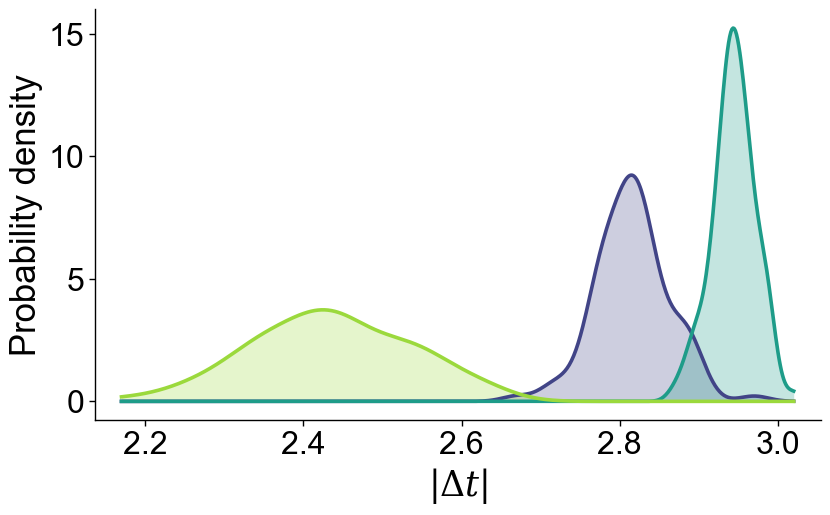

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

# =====================================================
# Style: Arial text + DejaVu Serif math
# Default fontsize = 20
# =====================================================
FONT_SIZE = 25

mpl.rcParams.update({
    # text
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,

    # axes / ticks
    "axes.titlesize": FONT_SIZE + 1,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,
    "xtick.labelsize": FONT_SIZE - 2,
    "ytick.labelsize": FONT_SIZE - 2,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,

    # legend
    "legend.fontsize": FONT_SIZE - 2,
    "legend.frameon": False,

    # math
    "mathtext.fontset": "dejavuserif",
    "mathtext.rm": "DejaVu Serif",
    "mathtext.it": "DejaVu Serif:italic",
    "mathtext.bf": "DejaVu Serif:bold",

    # pdf embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

viridis = get_cmap("viridis")

# =====================================================
# Load data
# =====================================================
data_er  = np.load("delta_t_bio_er.npz", allow_pickle=True)
data_ba  = np.load("delta_t_bio_ba.npz", allow_pickle=True)
data_sbm = np.load("delta_t_bio_sbm.npz", allow_pickle=True)

# |Δt|
dt_er  = np.abs(data_er["delta_t"])
dt_ba  = np.abs(data_ba["delta_t"])
dt_sbm = np.abs(data_sbm["delta_t"])

# Remove NaN / Inf
dt_er  = dt_er[np.isfinite(dt_er)]
dt_ba  = dt_ba[np.isfinite(dt_ba)]
dt_sbm = dt_sbm[np.isfinite(dt_sbm)]

# =====================================================
# KDE (Scott rule)
# =====================================================
kde_er  = gaussian_kde(dt_er)
kde_ba  = gaussian_kde(dt_ba)
kde_sbm = gaussian_kde(dt_sbm)

xmin = min(dt_er.min(), dt_ba.min(), dt_sbm.min())
xmax = max(dt_er.max(), dt_ba.max(), dt_sbm.max())

# Grid KDE
xgrid = np.linspace(xmin, xmax, 600)
y_er  = kde_er(xgrid)
y_ba  = kde_ba(xgrid)
y_sbm = kde_sbm(xgrid)

# =====================================================
# Plot settings
# =====================================================
lw = 2.6
fill_alpha = 0.26

c_er  = viridis(0.20)
c_ba  = viridis(0.55)
c_sbm = viridis(0.85)

# =====================================================
# Bigger figure + x-axis padding (key changes)
# =====================================================

fig_width  = 220 / 25.4  # ~10.24 in
fig_height = 140 / 25.4   # Original 165 / 25.4 


xpad_frac = 0.04  
xrange = xmax - xmin
xlo = xmin - xpad_frac * xrange
xhi = xmax + xpad_frac * xrange

# =====================================================
# Main figure (NO legend, NO grid)
# =====================================================
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

ax.plot(xgrid, y_er,  lw=lw, color=c_er)
ax.fill_between(xgrid, 0.0, y_er,  color=c_er,  alpha=fill_alpha, linewidth=0)

ax.plot(xgrid, y_ba,  lw=lw, color=c_ba)
ax.fill_between(xgrid, 0.0, y_ba,  color=c_ba,  alpha=fill_alpha, linewidth=0)

ax.plot(xgrid, y_sbm, lw=lw, color=c_sbm)
ax.fill_between(xgrid, 0.0, y_sbm, color=c_sbm, alpha=fill_alpha, linewidth=0)

ax.set_xlabel(r"$|\Delta t|$")
ax.set_ylabel("Probability density")


ax.set_xlim(xlo, xhi)


ax.xaxis.set_major_locator(MaxNLocator(nbins=6))

# Axes styling (NO grid)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out")

fig.tight_layout(pad=0.8)
fig.savefig("fig_kde_delta_t_bio_compare2.pdf", format="pdf", bbox_inches="tight")
plt.show()

# =====================================================
# Separate legends (3 PDFs, one label each)
# =====================================================
def save_single_legend_pdf(filename, color, label):
    handle = Line2D([0], [0], color=color, lw=lw, label=label)

    fig_leg = plt.figure(figsize=(2.4, 2.4))
    fig_leg.legend(
        handles=[handle],
        loc="center",
        frameon=False,
        handlelength=2.0
    )
    fig_leg.tight_layout(pad=0.2)
    fig_leg.savefig(filename, format="pdf", bbox_inches="tight")
    plt.close(fig_leg)


save_single_legend_pdf("legend_ER.pdf",  c_er,  "ER")
save_single_legend_pdf("legend_BA.pdf",  c_ba,  "BA")
save_single_legend_pdf("legend_SBM.pdf", c_sbm, "SBM")

